In [20]:
import seaborn as sns 
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans 
import pandas as pd 
import matplotlib.pyplot as plt
import matplotlib.pyplot as plot
from sklearn.cluster import KMeans as KM

In [21]:
iris = load_iris()

X = pd.DataFrame(iris.data)
X.columns = iris.feature_names
y = iris.target

In [22]:
X

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


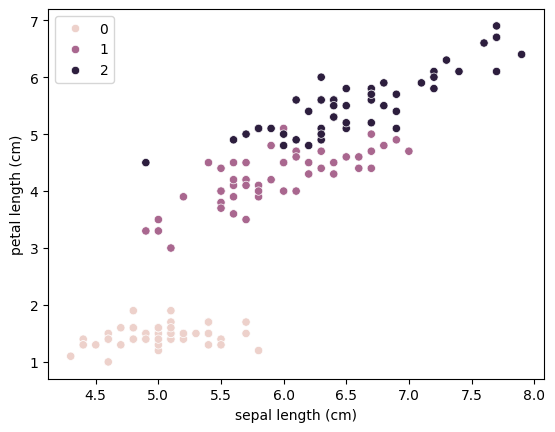

In [23]:
# Visaulize 

sns.scatterplot(
    x= X.iloc[:,0], 
    y=X.iloc[:,2] , 
    hue=y
)
plt.show()

In [24]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

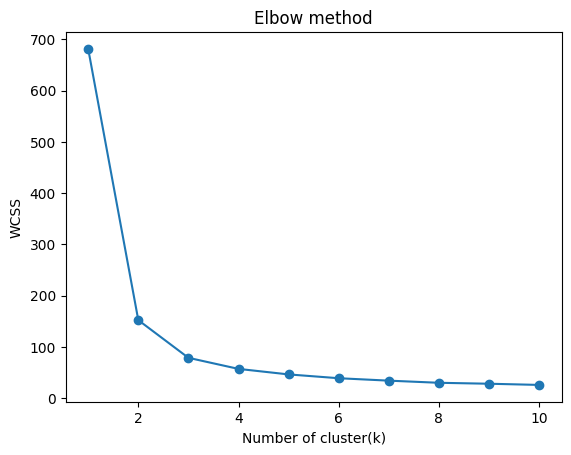

In [25]:
# Elbow method 
wcss = []
for k in range (1,11) :
    model = KM(
        n_clusters=k , 
        random_state=42 , 
        n_init=10
    )
    model.fit(X)
    wcss.append(model.inertia_)
plot.Figure(figsize=(8, 5))
plot.plot(range(1,len(wcss) + 1) , wcss , marker= 'o')
plot.xlabel("Number of cluster(k)")
plot.ylabel("WCSS")
plot.title("Elbow method")
plot.show()

In [26]:
# dimensionility reduction using PCA 

from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca_data = pca.fit_transform(X_scaled)

<Axes: >

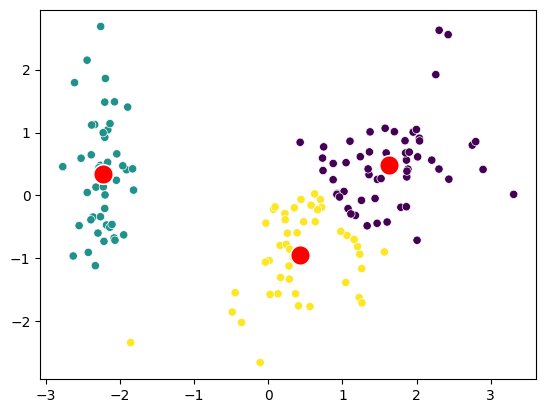

In [27]:
# Kmeans 

KMeans = KMeans(n_clusters=3 , random_state=10)
labels = KMeans.fit_predict(pca_data)

sns.scatterplot(x=pca_data[:,0] , y=pca_data[:,1] , c=labels)
sns.scatterplot(x=KMeans.cluster_centers_[:,0] , y=KMeans.cluster_centers_[:,1 ] , markers="X" , c="red", s=200)